# East Africa Farm Input Prices 2026

Agro-dealer prices and stock: seeds, pesticides, fertilizer, Kenya and Uganda. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/east-africa-farm-input-prices) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("east_africa_farm_input_prices_2026.csv", "https://huggingface.co/datasets/nuasense/east-africa-farm-input-prices/resolve/main/data/prices/prices.parquet")
print(f"{len(df):,} rows")
df.head()

6,130 rows


,country,currency,category,dealer_category,product,brand,formulation,pack_size,pack_unit,month,median_price,median_price_per_unit,in_stock_share,backorder_share,dealers,daily_readings
0,KE,KES,acaricide,acaricide,bravecto,NaN,NaN,NaN,NaN,2026-09,4097.0,NaN,1.0,0.0,1,19
1,KE,KES,acaricide,acaricide,bravecto,NaN,NaN,NaN,NaN,2026-10,4097.0,NaN,1.0,0.0,1,31
2,KE,KES,acaricide,acaricide,dabotik-acaricide,truvets,EC,NaN,NaN,2026-09,141.0,NaN,1.0,0.0,1,24
3,KE,KES,acaricide,acaricide,dabotik-acaricide,truvets,EC,NaN,NaN,2026-10,141.0,NaN,1.0,0.0,1,31
4,KE,KES,acaricide,acaricide,dominex,NaN,NaN,NaN,NaN,2026-09,250.0,NaN,1.0,0.0,1,23


## What is listed

Products per category and country, and how often they were in stock.

In [2]:
products = df.drop_duplicates(["country", "product"])
pd.crosstab(products.category, products.country).sort_values("KE", ascending=False)

country,KE,UG
category,,
mixed_crop_inputs,1082,0
seed,519,63
insecticide,283,61
fungicide,150,28
animal_health_and_feed,136,0
herbicide,109,35
fertilizer,90,28
foliar_feed,82,0
acaricide,28,0


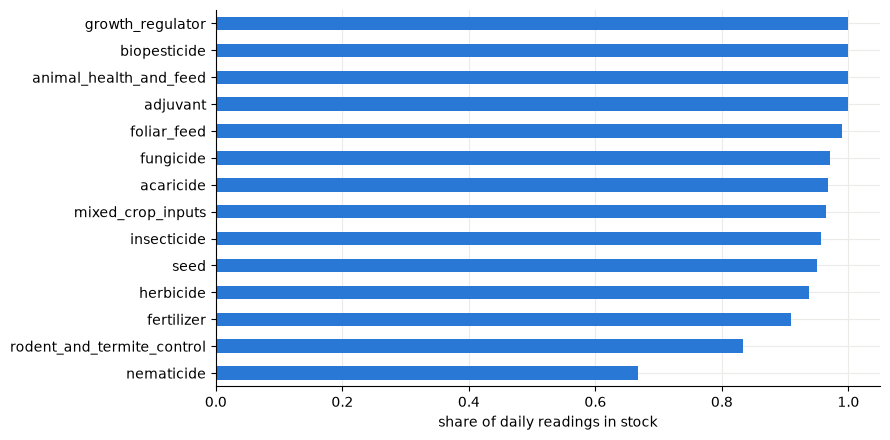

In [3]:
stock = df.groupby("category").in_stock_share.mean().sort_values()
ax = stock.plot.barh(color=BLUE)
ax.set_xlabel("share of daily readings in stock"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## Insecticides per litre in Kenya

The median price per litre by formulation, where the pack is a liquid.

In [4]:
ins = df[(df.country == "KE") & (df.category == "insecticide") & (df.pack_unit == "l") & df.median_price_per_unit.notna()]
ins.groupby("formulation").median_price_per_unit.agg(["count", "median"]).sort_values("count", ascending=False).head(10).round(0)

,count,median
formulation,,
SC,56,9400.0
EC,48,4900.0
CS,14,29600.0
SL,14,7399.0
OD,4,9800.0
EW,2,48214.0
ZC,2,14500.0


## September to October

Products listed in both months: how many got dearer, cheaper, or stayed.

In [5]:
w = df.pivot_table(index=["country", "product", "pack_size"], columns="month", values="median_price").dropna()
if w.shape[1] >= 2:
    a, b = w.columns[-2], w.columns[-1]
    change = (w[b] / w[a] - 1) * 100
    print(f"{len(w):,} products in both {a} and {b}")
    print(pd.cut(change, [-1000, -0.5, 0.5, 1000], labels=["cheaper", "same", "dearer"]).value_counts())

1,541 products in both 2026-09 and 2026-10
same       1523
dearer       15
cheaper       3
Name: count, dtype: int64


## The full data

This sample holds monthly medians. The NuaSense API serves the daily series per dealer, with lowest and highest offer, discount and active-ingredient loading.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/price-intelligence/input-prices/).

In [6]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/input-prices", start="-30d", limit=200, country="ke", category="fungicide")
    display(pd.DataFrame(rows).head())
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
